# code_052 · Preprocessing as a learned pipeline

**Book:** section 11.1. A self-contained preprocessing laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_11_GUIDE.md), [run evidence](../CHAPTER_11_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_052).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. Model-family comparisons and documentary contract checks retain their declared limits; there are no field-validity or universal-preprocessing claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1152;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1152


<a id="boundary"></a>
## Declare the fitting boundary before transforming

Generate 160 independent teaching members with two measured inputs, a noisy linear response in mm, and 20% absent first inputs. The final 40 rows have a broader first-input distribution by construction. Four contiguous validation blocks therefore assess specified blocks of this mixed population, not a chronological deployment claim. Compare exactly the same 5-neighbor regressor and folds. The deliberately invalid alternative fits the imputer and scaler on all 160 inputs before holding out a block. It uses no held-out labels, but still uses unavailable held-out input statistics. This need not improve the numerical score in every realization.

Finite/non-infinite checks are deterministic schema checks: NaN is allowed here, infinity is not. The imputer's median and scaler's moments are learned and belong inside each fold. No candidate is selected or final performance claimed from these diagnostic folds.


In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold,cross_val_score
from sklearn.metrics import mean_squared_error
x=rng.normal(size=(160,2));x[120:,0]*=5
y=1+1.5*x[:,0]+.7*x[:,1]+rng.normal(0,.25,160)
X=x.copy();X[rng.random(160)<.2,0]=np.nan
assert X.shape==(160,2) and not np.isinf(X).any() and np.isfinite(y).all()
folds=list(KFold(4,shuffle=False).split(X));valid=[];invalid=[];states=[]
global_imputer=SimpleImputer(strategy='median');global_scaler=StandardScaler()
Z=global_scaler.fit_transform(global_imputer.fit_transform(X))
for tr,va in folds:
 pipe=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),KNeighborsRegressor(n_neighbors=5))
 pipe.fit(X[tr],y[tr]);valid.append(float(mean_squared_error(y[va],pipe.predict(X[va]))))
 invalid.append(float(mean_squared_error(y[va],KNeighborsRegressor(n_neighbors=5).fit(Z[tr],y[tr]).predict(Z[va]))))
 imp=pipe[0];sc=pipe[1];train_filled=imp.transform(X[tr])
 np.testing.assert_allclose(imp.statistics_,np.nanmedian(X[tr],axis=0));np.testing.assert_allclose(sc.mean_,train_filled.mean(axis=0))
 states.append({'training_rows':len(tr),'median0':float(imp.statistics_[0]),'scale0':float(sc.scale_[0])})
check=-cross_val_score(make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),KNeighborsRegressor(n_neighbors=5)),X,y,cv=folds,scoring='neg_mean_squared_error')
np.testing.assert_allclose(check,valid);assert not np.allclose(valid,invalid)
RESULTS['fold_MSE_mm2']={'fold_only':valid,'all_input_statistics_invalid':invalid};RESULTS['mean_fold_MSE_mm2']={'fold_only':float(np.mean(valid)),'all_input_statistics_invalid':float(np.mean(invalid))};RESULTS['fold_states']=states
print(RESULTS['mean_fold_MSE_mm2'])


{'fold_only': 9.956478941113438, 'all_input_statistics_invalid': 10.557481933292284}


<a id="diagram"></a>
## Trace fit and transform arrows separately

Training inputs fit the median and scale, and transformed training inputs fit model coefficients/state. Validation inputs use only stored transforms; their labels score predictions. The displayed arrows represent the legal information flow, not a fitted causal graph.


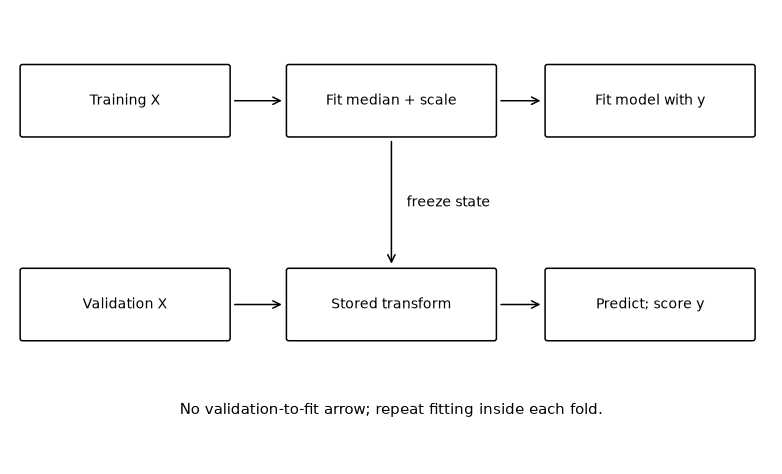

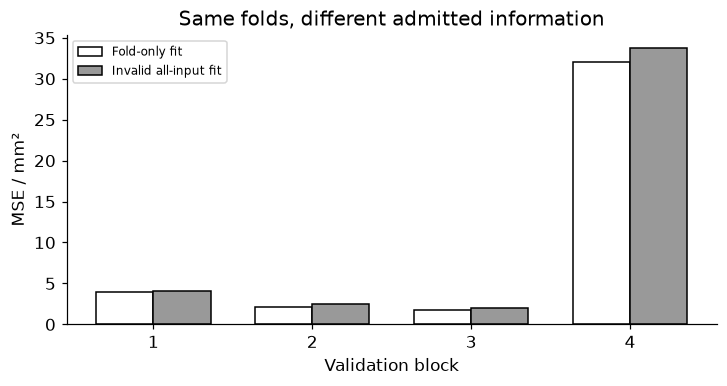

In [3]:
from matplotlib.patches import FancyBboxPatch,FancyArrowPatch
fig,ax=plt.subplots(figsize=(7,4.2));ax.axis('off');ax.set(xlim=(0,10),ylim=(0,6))
boxes=[(1.5,4.8,'Training X'),(5,4.8,'Fit median + scale'),(8.4,4.8,'Fit model with y'),(1.5,2.1,'Validation X'),(5,2.1,'Stored transform'),(8.4,2.1,'Predict; score y')]
for cx,cy,label in boxes:
 ax.add_patch(FancyBboxPatch((cx-1.35,cy-.45),2.7,.9,boxstyle='round,pad=.03',fc='white'));ax.text(cx,cy,label,ha='center',va='center',fontsize=9)
for start,end in [((2.9,4.8),(3.6,4.8)),((6.4,4.8),(7,4.8)),((2.9,2.1),(3.6,2.1)),((6.4,2.1),(7,2.1)),((5,4.3),(5,2.6))]:
 ax.add_patch(FancyArrowPatch(start,end,arrowstyle='->',mutation_scale=12))
ax.text(5.2,3.4,'freeze state',fontsize=9);ax.text(5,.65,'No validation-to-fit arrow; repeat fitting inside each fold.',ha='center',fontsize=10);plt.show()
fig,ax=plt.subplots(figsize=(6.5,3.4));k=np.arange(4);ax.bar(k-.18,valid,.36,color='white',edgecolor='black',label='Fold-only fit');ax.bar(k+.18,invalid,.36,color='.6',edgecolor='black',label='Invalid all-input fit');ax.set(xticks=k,xticklabels=np.arange(1,5),xlabel='Validation block',ylabel='MSE / mm²',title='Same folds, different admitted information');ax.legend(fontsize=8);plt.show()


<a id="inference"></a>
## Keep state fixed across prediction batches

Freeze an example on the first 120 members and predict three rows separately and as a batch. This is an inference consistency test, not a new assessment score. Re-fitting on the request batch would change the meaning of the inputs. Exact array checks show that transform/predict do not change stored state; a deliberate all-input refit above is separately labeled invalid.


In [4]:
frozen=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),KNeighborsRegressor(n_neighbors=5)).fit(X[:120],y[:120]);before=frozen[1].mean_.copy()
batch=frozen.predict(X[120:123]);single=np.array([frozen.predict(X[i:i+1])[0] for i in range(120,123)])
np.testing.assert_allclose(batch,single);np.testing.assert_array_equal(before,frozen[1].mean_)
RESULTS['batch_invariance_passed']=True;RESULTS['prediction_batch_size']=3


In [5]:
summary={'example_id':'code_052','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['deterministic validation versus learned transforms', 'fold-only imputation and scaling', 'paired leakage audit', 'stored state and batch-invariant inference'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["deterministic validation versus learned transforms", "fold-only imputation and scaling", "paired leakage audit", "stored state and batch-invariant inference"], "elapsed_seconds": 0.314, "example_id": "code_052", "hardware": "Darwin arm64 CPU", "results": {"batch_invariance_passed": true, "fold_MSE_mm2": {"all_input_statistics_invalid": [4.102840025924159, 2.49456945004331, 1.9399562005111204, 33.69256205669055], "fold_only": [3.93542322856005, 2.094756612210793, 1.772744127803391, 32.02299179587952]}, "fold_states": [{"median0": -0.2312240501687607, "scale0": 2.2621103141518284, "training_rows": 120}, {"median0": -0.015475131234732821, "scale0": 2.23468517306762, "training_rows": 120}, {"median0": -0.13126423242964408, "scale0": 2.271700167885223, "training_rows": 120}, {"median0": -0.2537863517330509, "scale0": 0.7884588954338944, "training_rows": 120}], "mean_fold_MSE_mm2": {"all_input_statistics_invalid": 10.557481933292284, "fold_o